# Emulator training using PyTorch

Part 1: Selecting the training data  
Part 2: Training the model on Temperature, oxygen, detritus, zooplankton, (iron)  
Part 3: Comparing the differently trained models (input parameter)  


# Part 1 : Selecting the training data

In [1]:
# import modules
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import pandas as pd
import glob
from dask import delayed, compute
import dask
import os

from dask.distributed import Client
client = Client(n_workers=16, threads_per_worker=1)

# set path to data files
PATH =  '/g/data/jk72/ao2582/ACCESS/wombathy/training/'
PATH_DATA_TRAINING =  '/g/data/jk72/ao2582/PyTorch/shadow_data/run_shadow_iaf_1/output/'
RANDOM_SEED = 42

FILES = glob.glob(PATH_DATA_TRAINING+ "*.nc")

PARAMS_MID = ["thetao", "mes", "phy", "zoo", "det", "dia", "bdet", "bac1","fe","o2", "det_vmove", "mlotst", "detremi", "bdetremi","poc1remi"]

In [2]:
def open_om3_variable(path_exp, varname):
    '''
    read in data from model run
    '''
    pattern = f"{path_exp}/access-om3.mom6.*d.{varname}.1day.mean.*.nc"
    files = sorted(glob.glob(pattern))
   # print(files)
    if not files:
        raise FileNotFoundError(f"No files found for variable {varname}")

    ds = xr.open_mfdataset(
        files,
        combine="nested",
        concat_dim="time",
        data_vars="minimal",
        coords="minimal",
        compat="override",
        decode_times=False,
        #chunks={"time": 365},  # Enable chunking per year
        #parallel=True  # Faster with many files
        )
    return ds

def load_data(params=PARAMS_MID, path_data=PATH_DATA_TRAINING):
    '''
    Load all variables and merge into one Dataset
    '''
    ds_list = []
    for var in params:
        try:
            ds_var = open_om3_variable(path_data, var)
            ds_list.append(ds_var)
            ds_var.close()
        except FileNotFoundError:
            print(f" Missing variable {var}")
       
    # Merge variables
    ds = xr.merge(ds_list, compat="override", join="override")
    # Fix time encoding
    ds = ds.assign_coords(time=ds.time)  # Ensure time is coordinate
    ds.time.attrs["units"] = "days since 0001-01-01 00:00:00"
    ds.time.attrs["calendar"] = "julian"
    # average over 2x2 grid and drop time_bnds object
    ds_om3 = xr.decode_cf(ds, decode_timedelta=False).compute().mean(dim=['xh','yh']).drop_vars('time_bnds')
    print('-- done')
    return ds_om3

In [3]:
# load training data
ds_training = load_data(params=PARAMS_MID, path_data=PATH_DATA_TRAINING)

# quick check to validate data is loaded properly 
len(ds_training.time)
print(ds_training)

# save to file ....

-- done
<xarray.Dataset> Size: 125MB
Dimensions:     (time: 29585, zl: 75, nv: 2)
Coordinates:
  * time        (time) object 237kB 0059-01-01 12:00:00 ... 0139-12-31 12:00:00
  * zl          (zl) float64 600B 0.5413 1.681 2.94 ... 5.511e+03 5.805e+03
  * nv          (nv) float64 16B 1.0 2.0
Data variables: (12/18)
    thetao      (time, zl) float32 9MB 11.55 11.55 11.55 ... 0.481 0.4691 0.4634
    average_T1  (time) datetime64[ns] 237kB 1958-01-01 1958-01-02 ... 2038-12-31
    average_T2  (time) datetime64[ns] 237kB 1958-01-02 1958-01-03 ... 2039-01-01
    average_DT  (time) float64 237kB 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0 1.0
    mes         (time, zl) float32 9MB 9.732e-08 9.732e-08 ... 9.662e-10
    phy         (time, zl) float32 9MB 1.732e-07 1.729e-07 ... 9.662e-10
    ...          ...
    o2          (time, zl) float32 9MB 0.0002776 0.0002782 ... 0.0001748
    det_vmove   (time, zl) float32 9MB 0.00023 0.00023 ... 0.00023 0.00023
    mlotst      (time) float32 118kB 35.66 48

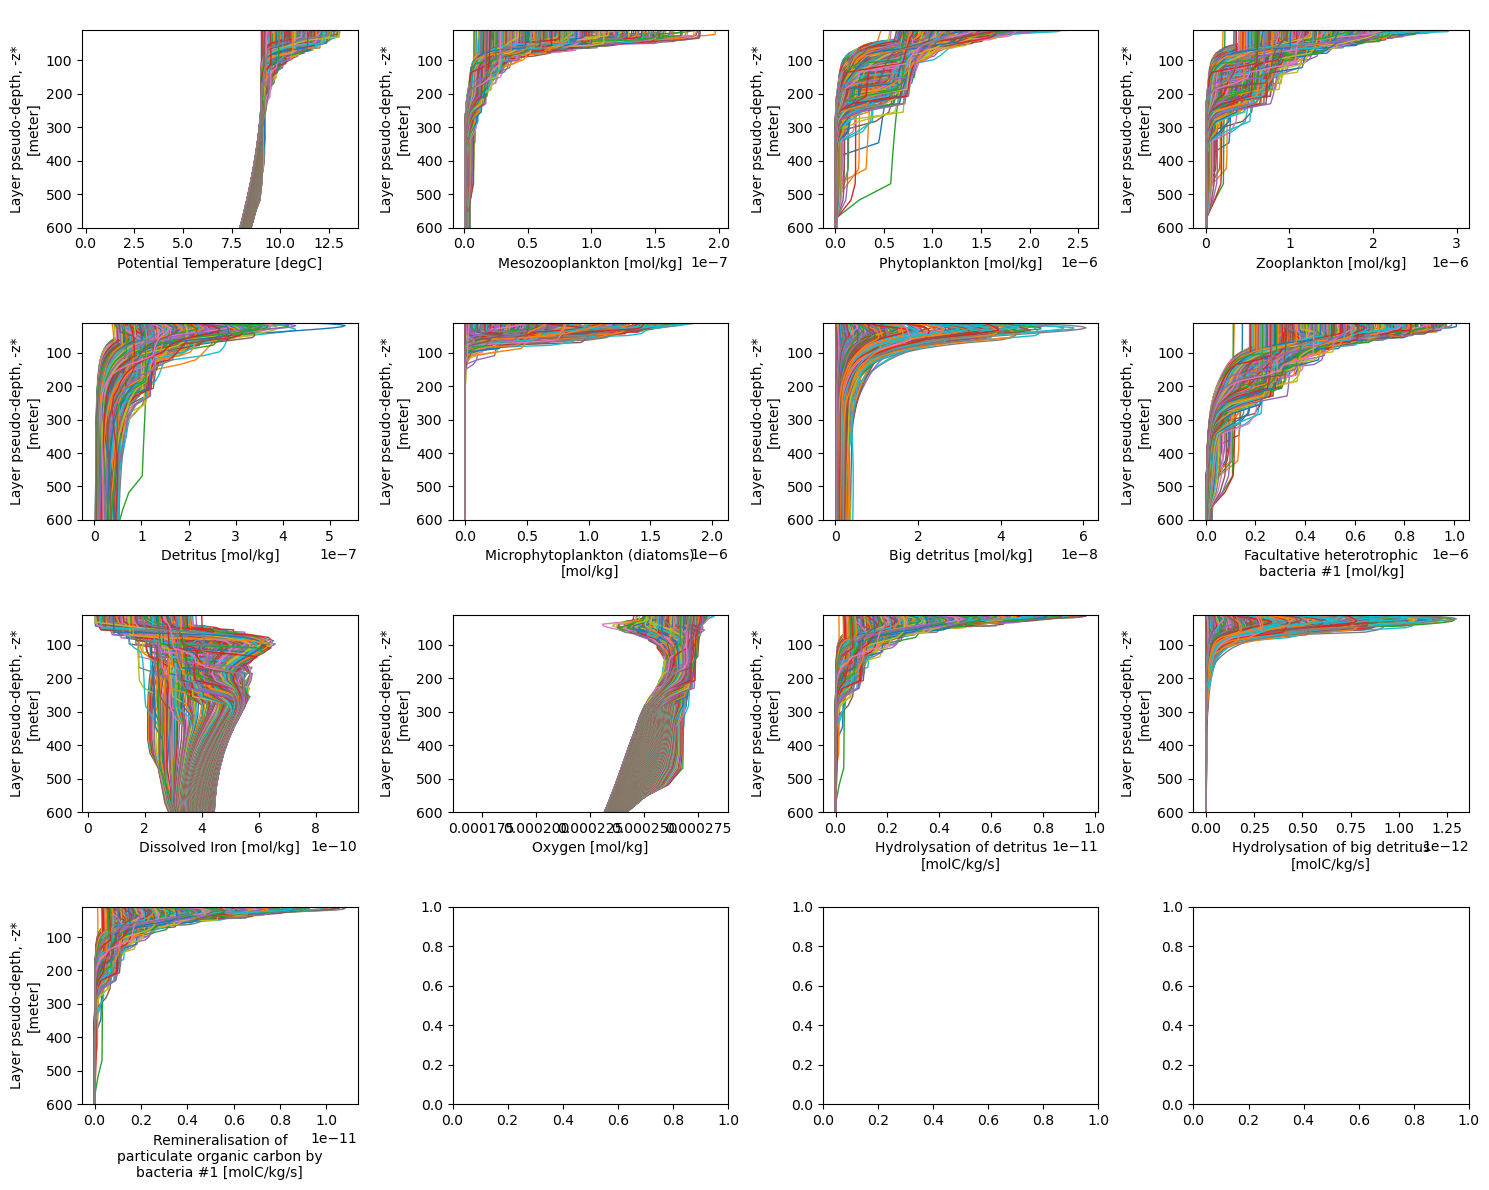

In [10]:
# check data distribution, VERY SLOW
ds = ds_training

# overview over parameter ranges
fig, axes = plt.subplots(4,4, figsize=(15,12), sharey=False)
axes = axes.flatten()
params = PARAMS_MID.copy()
for param in ["mlotst", "det_vmove"]:
    if param in params:
        params.remove(param)

for i, param in enumerate(params):
    ax=axes[i]
    for yr in list(ds.groupby('time.year').groups.keys())[1:-1]:
        ds_exp = ds.groupby('time.year')[yr]
        for day in ds_exp.isel(time=np.arange(1,360,30)).time:
            ds_exp_time = ds_exp.sel(time=day)
            ds_exp_time[f'{param}'].plot(y='zl', ax = ax, linewidth=1)
    ax.set_title(' ')
    ax.set_ylim(600,10)

plt.tight_layout()
plt.show()

thetao
mes
phy
zoo
det
dia
bdet
bac1
fe
o2
detremi
bdetremi


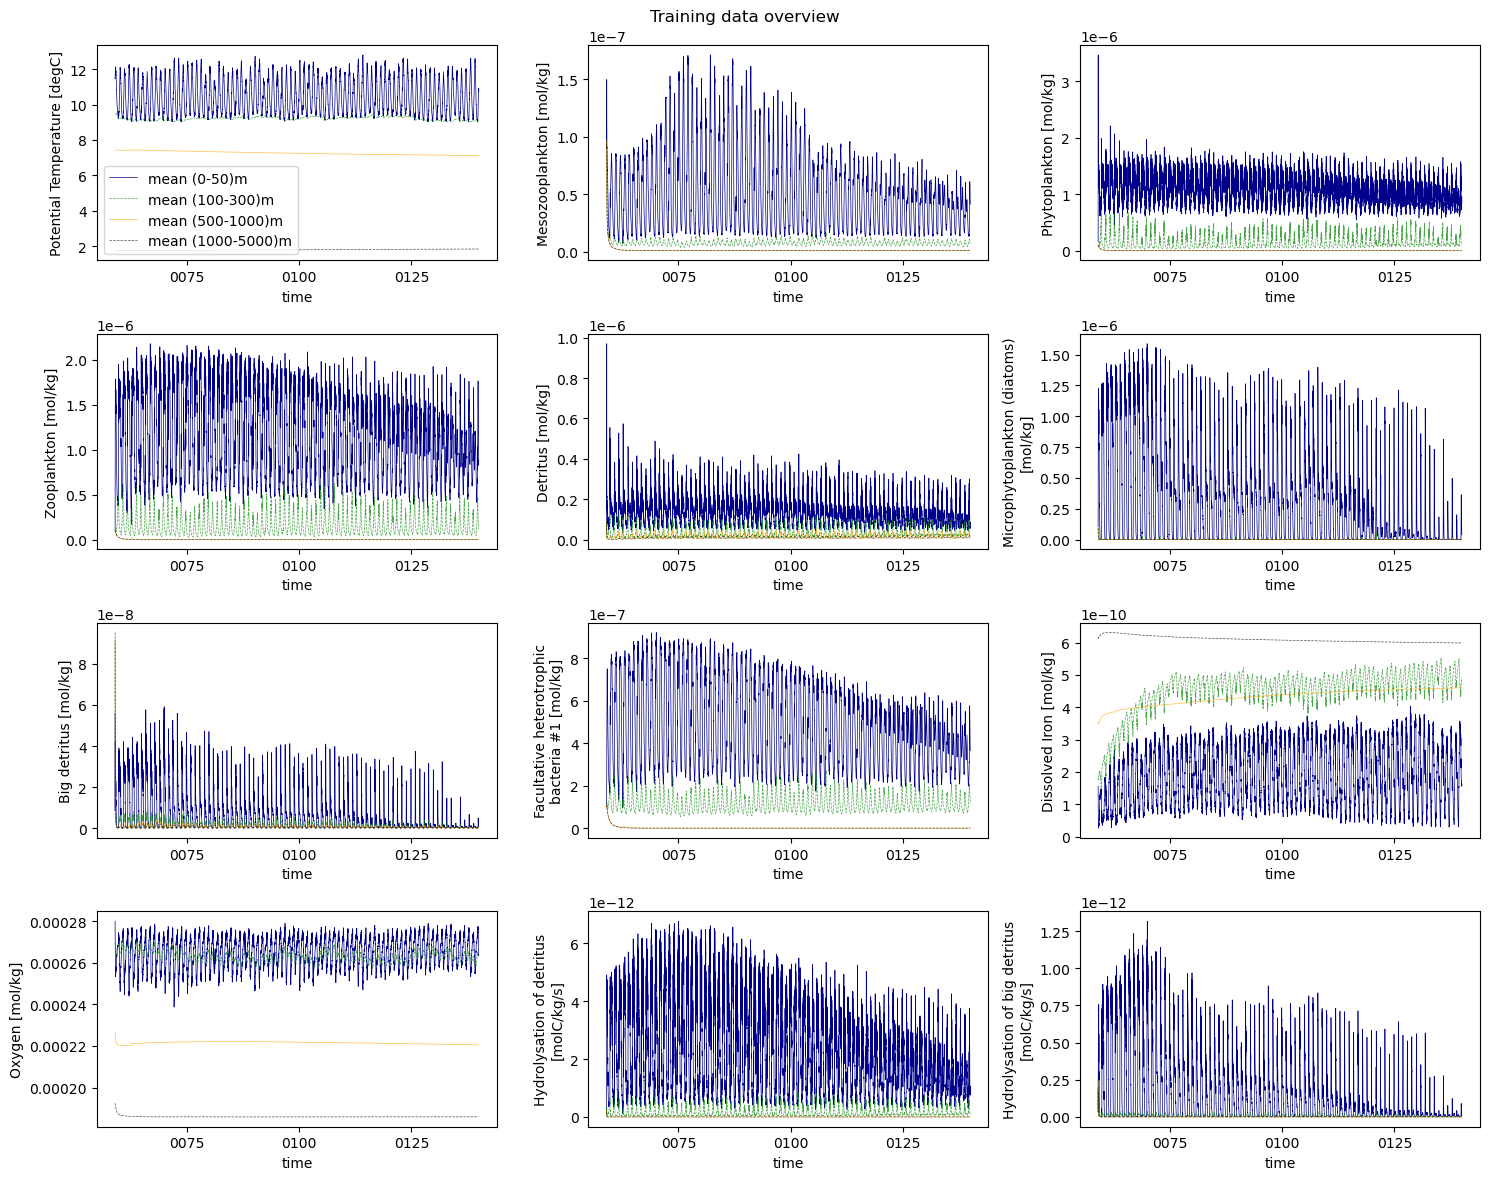

In [18]:
# investigate timeseries for training parameter

params = PARAMS_MID.copy()
for param in ["mlotst", "det_vmove"]:
    if param in params:
        params.remove(param)

fig, axes = plt.subplots(4, 3, figsize=(15, 12), sharey=False)
axes = axes.flatten()

for ax, param in zip(axes, params):
    print(param)
    ds_training[param].sel(zl=np.arange(0,50), method='nearest').mean(dim='zl').plot(x='time', ax = ax, linewidth=0.5, color='darkblue', alpha=1, linestyle='-', label='mean (0-50)m')
    ds_training[param].sel(zl=np.arange(100,300), method='nearest').mean(dim='zl').plot(x='time', ax = ax, linewidth=0.5, color='green', alpha=0.7, linestyle='--', label='mean (100-300)m')
    ds_training[param].sel(zl=np.arange(500,1000), method='nearest').mean(dim='zl').plot(x='time', ax = ax, linewidth=0.5, color='orange', alpha=0.7, linestyle='-', label='mean (500-1000)m')
    ds_training[param].sel(zl=np.arange(1000,5000), method='nearest').mean(dim='zl').plot(x='time', ax = ax, linewidth=0.5, color='black', alpha=0.7, linestyle='--', label='mean (1000-5000)m')

    
axes[0].legend()
fig.suptitle('Training data overview')
plt.tight_layout()
plt.show()

not plotted (excluded, missing, or no depth axis): ['det_vmove', 'mlotst']


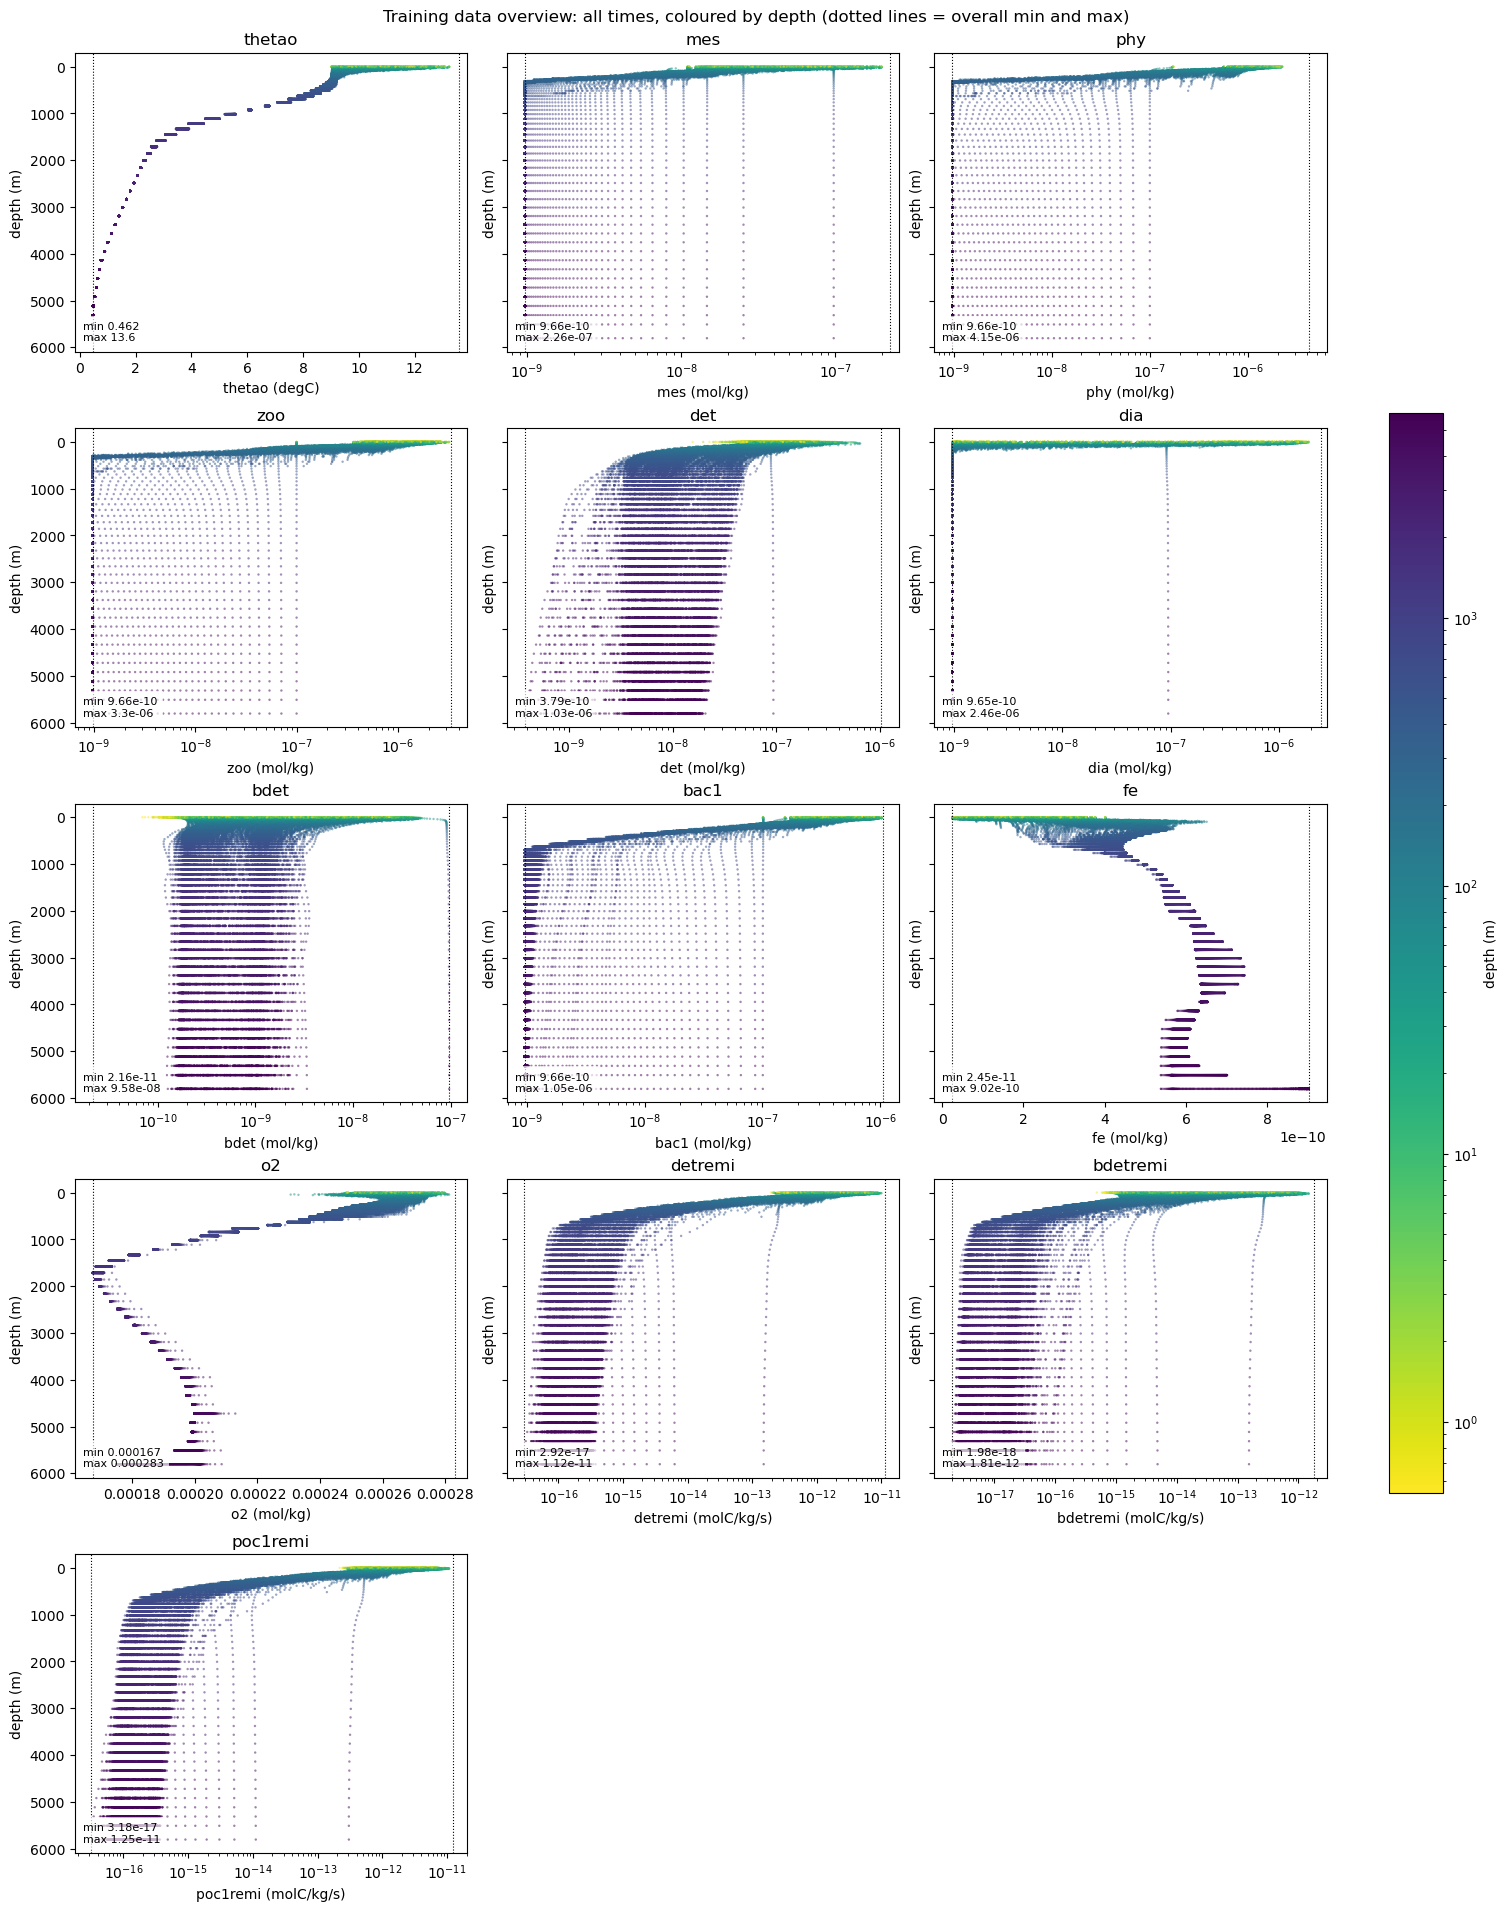

,min,1st pct,median,99th pct,max,% non-positive
parameter,,,,,,
thetao,0.462,0.463,8.81,12.3,13.6,0
mes,9.66e-10,9.66e-10,1.04e-09,1.32e-07,2.26e-07,0
phy,9.66e-10,9.66e-10,9.66e-10,1.79e-06,4.15e-06,0
zoo,9.66e-10,9.66e-10,9.66e-10,2.24e-06,3.3e-06,0
det,3.79e-10,1.63e-09,1.88e-08,2.71e-07,1.03e-06,0
dia,9.65e-10,9.65e-10,9.66e-10,1.42e-06,2.46e-06,0
bdet,2.16e-11,1.52e-10,5.49e-10,3.05e-08,9.58e-08,0
bac1,9.66e-10,9.66e-10,1e-08,8.79e-07,1.05e-06,0
fe,2.45e-11,3.34e-11,4.71e-10,7.41e-10,9.02e-10,0


In [30]:
# Overview of the value ranges of the training data: one panel per parameter, value against depth,
# every point coloured by depth, no time axis. Notebook cell; nothing is saved.
# Needs: ds_training (dims (time, zl)) and PARAMS_MID (list of variable names).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize

EXCLUDE = {"mlotst", "det_vmove"}   # variables left out (mlotst has no depth axis)
N_MAX = 40_000                      # points drawn per panel (the statistics use ALL values)
Y_VAR = None                        # None: depth on the y axis. A variable name, e.g. "det", gives a
                                    # scatter of every parameter against that variable (joint ranges)
LOG_DEPTH_COLOUR = True             # logarithmic colour scale for depth (shows the upper ocean better)
CMAP = "viridis_r"                  # shallow = yellow, deep = purple
NCOLS = 3


def field(da):
    """Values as float64, dimensions ordered (time, zl)."""
    return da.squeeze().transpose("time", "zl").values.astype(float)


rng = np.random.default_rng(0)
zl = ds_training["zl"].values
params = [p for p in PARAMS_MID
          if p not in EXCLUDE and p in ds_training and "zl" in ds_training[p].dims]
skipped = [p for p in PARAMS_MID if p not in params]
if skipped:
    print("not plotted (excluded, missing, or no depth axis):", skipped)

depth_norm = (LogNorm(vmin=zl[zl > 0].min(), vmax=zl.max()) if LOG_DEPTH_COLOUR
              else Normalize(vmin=zl.min(), vmax=zl.max()))
y_arr = field(ds_training[Y_VAR]) if Y_VAR else None

nrows = int(np.ceil(len(params) / NCOLS))
fig, axes = plt.subplots(nrows, NCOLS, figsize=(5.0 * NCOLS, 3.8 * nrows),
                         sharey=(Y_VAR is None), squeeze=False, constrained_layout=True)
axes = axes.ravel()
rows = {}
for ax, p in zip(axes, params):
    arr = field(ds_training[p])
    finite = arr[np.isfinite(arr)]
    pos = finite[finite > 0]
    # logarithmic axis only when the values are essentially all positive and span > 2 decades
    use_log = pos.size > 0.99 * finite.size and pos.max() / pos.min() > 100
    vmin, vmax = float(finite.min()), float(finite.max())
    rows[p] = {"min": vmin, "1st pct": np.percentile(finite, 1), "median": np.median(finite),
               "99th pct": np.percentile(finite, 99), "max": vmax,
               "% non-positive": 100 * float(np.mean(finite <= 0))}

    # thin out by TIME (every stride-th record) so that every depth is represented equally
    stride = max(1, int(np.ceil(arr.size / N_MAX)))
    x = arr[::stride].ravel()
    d = np.broadcast_to(zl, arr[::stride].shape).ravel()
    y = d if y_arr is None else y_arr[::stride].ravel()
    ok = np.isfinite(x) & np.isfinite(y) & ((x > 0) if use_log else True)
    idx = rng.permutation(np.flatnonzero(ok))                    # random drawing order: no layer hides another
    sc = ax.scatter(x[idx], y[idx], c=d[idx], s=3, alpha=0.5, cmap=CMAP, norm=depth_norm,
                    linewidths=0, rasterized=True)
    if use_log:
        ax.set_xscale("log")
    for v in (vmin, vmax):
        if not use_log or v > 0:
            ax.axvline(v, color="k", ls=":", lw=0.8)
    ax.text(0.02, 0.03, f"min {vmin:.3g}\nmax {vmax:.3g}", transform=ax.transAxes, fontsize=8,
            va="bottom", bbox=dict(facecolor="white", alpha=0.7, lw=0))
    units = ds_training[p].attrs.get("units", "")
    ax.set_title(p)
    ax.set_xlabel(f"{p} ({units})" if units else p)
    if Y_VAR is None:
        ax.set_ylabel("depth (m)")
    else:
        ax.set_ylabel(Y_VAR)
for ax in axes[len(params):]:
    ax.set_visible(False)
if Y_VAR is None:
    axes[0].invert_yaxis()
fig.colorbar(plt.cm.ScalarMappable(norm=depth_norm, cmap=CMAP),      # own mappable: no transparency
             ax=axes[:len(params)].tolist(), label="depth (m)", shrink=0.6)
fig.suptitle("Training data overview: all times, coloured by depth (dotted lines = overall min and max)")
plt.show()

table = pd.DataFrame(rows).T.rename_axis("parameter")
display(table.apply(lambda col: col.map(lambda v: f"{v:.3g}")))      # significant digits, not decimals

# Part 2: Train the model

In [4]:
import xarray as xr
import pandas as pd
import glob
import matplotlib.pyplot as plt
import numpy as np
import copy
import time
import shap

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"


PATH_DATA =  '/../../../g/data/jk72/ao2582/PyTorch/training_data/'

# load data
#scenario = 'sobol_training_001_test'
#ds_training =  xr.open_dataset(path_data +  f'{scenario}.nc',decode_timedelta=True )

# retain validation data, skip first year
ds_nn=ds_training.isel(time=np.arange(365,len(ds_training.time))).rename_dims({'time': 'prof'})
depth = ds_nn.zl.data
n_prof = len(ds_nn.prof)


# ADJUST TRAINING PARAMS
FEATURES = ['Temperature','Oxygen', 'Detritus', 'Zoo']
TRAINING_DATA = [ds_nn.thetao.data, ds_nn.o2, (ds_nn.det.data+ds_nn.bdet.data), (ds_nn.zoo.data+ds_nn.mes.data)] # ds_nn.fe] 

LOG_COLS = [2, 3]  
EPS = 1e-20

In [14]:
def transform_X(A, log_cols=LOG_COLS, eps=EPS):
    '''
    Log transform parameters for training
    '''
    A = A.copy()
    A[:, log_cols] = np.log(A[:, log_cols] + eps)
    return A
    
def transform_y(a, eps=EPS):
    '''
    Log transform parameters for training
    '''
    return np.log(a + eps)   # model predicts log(rate)


# Model: simple MLP
class MLP(nn.Module):
    def __init__(self, n_in, hidden=64, n_layers=3):
        super().__init__()
        layers, d = [], n_in
        for _ in range(n_layers):
            layers += [nn.Linear(d, hidden), nn.SiLU()]
            d = hidden
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(-1)


# functions for model training
def eval_loss(X, y, chunk=500_000):
    """Mean squared error over a (possibly huge) array, evaluated in chunks."""
    model.eval()
    tot = 0.0
    with torch.no_grad():
        for i in range(0, len(X), chunk):
            xb, yb = X[i:i + chunk].to(device), y[i:i + chunk].to(device)
            tot += loss_fn(model(xb), yb).item() * len(xb)
    return tot / len(X)
 
 
def factor(mse):
    """Typical error as a multiplicative factor on the rate (standardised MSE -> exp(RMSE in ln units))."""
    return float(np.exp(np.sqrt(mse) * y_std))

def predict_rate(X_raw, batch_size=200000):
    """Raw features (n, n_features), in training units and column order -> rate (n,) in physical units."""
    Xn = (transform_X(np.asarray(X_raw, dtype=np.float64)) - x_mean) / x_std   # log columns, then scale
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(Xn), batch_size):
            xb = torch.tensor(Xn[i:i + batch_size], dtype=torch.float32).to(device)
            out.append(model(xb).cpu().numpy())
    return np.exp(np.concatenate(out) * y_std + y_mean) - eps                  # undo scaling, then undo the log

In [6]:
X = np.stack(TRAINING_DATA, axis=-1)
y = ds_nn.poc1remi.data


# Split by PROF (last 20% held out), not randomly, to avoid leakage???? 
# flatten dims (prof * depth)
split = int(0.8 * (n_prof*0.9))
X_train, X_test, X_val = X[:split].reshape(-1, X.shape[-1]), X[split: int(n_prof*0.9)].reshape(-1, X.shape[-1]), X[int(n_prof*0.9):].reshape(-1, X.shape[-1])
y_train, y_test, y_val = y[:split].reshape(-1), y[split:int(n_prof*0.9)].reshape(-1), y[int(n_prof*0.9):].reshape(-1)

# double check dimensionality
print(n_prof, split, n_prof-int(n_prof*0.9))
ds_nn.dims
print(n_prof)
print(X.shape)
print(y.shape)
print(split)
print(9600*75*0.8)

print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)


# Log-transform skewed quantities (choose the columns that are positive & skewed)
# change to float64 
X = X.astype(np.float64)
y = y.astype(np.float64)

# transform
Xtr, Xte, Xva = transform_X(X_train), transform_X(X_test), transform_X(X_val)
ytr, yte, yva = transform_y(y_train), transform_y(y_test), transform_y(y_val)

# Normalise using TRAINING statistics only
x_mean, x_std = Xtr.mean(0), Xtr.std(0) + EPS
y_mean, y_std = ytr.mean(), ytr.std() + EPS
Xtr, Xte, Xva = (Xtr - x_mean) / x_std, (Xte - x_mean) / x_std, (Xva - x_mean) / x_std
ytr, yte, yva = (ytr - y_mean) / y_std, (yte - y_mean) / y_std, (yva - y_mean) / y_std


print(Xtr.shape, Xte.shape, Xva.shape)
print(ytr.shape, yte.shape, yva.shape)

# call model 
model = MLP(n_in=Xtr.shape[1]).to(device)


29220 21038 2922
29220
(29220, 75, 4)
(29220, 75)
21038
576000.0
(1577850, 4)
(394500, 4)
(1577850,)
(394500,)
(1577850, 4) (394500, 4) (219150, 4)
(1577850,) (394500,) (219150,)


In [7]:
# training loop

# Needs from the session: model, device, to_t, Xtr, ytr (training arrays, normalised),
# Xva, yva (validation arrays, normalised; NOT the test set), y_std (scaling of ln(rate)).
 
# ---- settings ----
EPOCHS = 40
BATCH = 8192                 # larger batches = less noisy gradients and faster epochs
LR_MAX, LR_MIN = 1e-3, 1e-5  # learning rate falls smoothly from LR_MAX to LR_MIN over all steps
WEIGHT_DECAY = 1e-5
PATIENCE = 8                 # stop if validation has not improved for this many epochs
# ------------------
 
loss_fn = nn.MSELoss()

# Convert to tensors / batches
to_t = lambda a: torch.tensor(a, dtype=torch.float32)
test_X, test_y = to_t(Xte).to(device), to_t(yte).to(device)

train_loader = DataLoader(TensorDataset(to_t(Xtr), to_t(ytr)), batch_size=BATCH, shuffle=True)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR_MAX, weight_decay=WEIGHT_DECAY)
total_steps = EPOCHS * len(train_loader)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps, eta_min=LR_MIN)
print(f"{len(Xtr):,} training samples, {len(train_loader)} steps per epoch, {total_steps} steps in total")
 
Xva_t, yva_t = to_t(Xva), to_t(yva)
 
best, best_state, bad = float("inf"), None, 0
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    tot = n = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        scheduler.step()                     # stepped every batch, not every epoch
        tot += loss.item() * len(xb)
        n += len(xb)
    train = tot / n                          # running average over the epoch
    val = eval_loss(Xva_t, yva_t)
    lr = optimizer.param_groups[0]["lr"]
    print(f"epoch {epoch:3d}  lr {lr:.1e}  train {train:.5f} (x{factor(train):.3f})  "
          f"val {val:.5f} (x{factor(val):.3f})  {time.time() - t0:.0f}s")
    if val < best * (1 - 1e-3):              # counts only as an improvement if it is >0.1 % better
        best, best_state, bad = val, copy.deepcopy(model.state_dict()), 0
    else:
        bad += 1
        if bad >= PATIENCE:
            print(f"no improvement for {PATIENCE} epochs: stopping")
            break
 
model.load_state_dict(best_state)
print(f"best validation loss {best:.5f}  (typical error factor x{factor(best):.3f})")

1,577,850 training samples, 193 steps per epoch, 7720 steps in total
epoch   1  lr 1.0e-03  train 0.07606 (x3.069)  val 0.00836 (x1.450)  26s
epoch   2  lr 9.9e-04  train 0.00656 (x1.390)  val 0.00611 (x1.374)  53s
epoch   3  lr 9.9e-04  train 0.00437 (x1.308)  val 0.00499 (x1.333)  78s
epoch   4  lr 9.8e-04  train 0.00384 (x1.287)  val 0.00474 (x1.323)  103s
epoch   5  lr 9.6e-04  train 0.00365 (x1.278)  val 0.00460 (x1.317)  129s
epoch   6  lr 9.5e-04  train 0.00346 (x1.270)  val 0.00440 (x1.310)  155s
epoch   7  lr 9.3e-04  train 0.00324 (x1.260)  val 0.00423 (x1.303)  180s
epoch   8  lr 9.1e-04  train 0.00296 (x1.247)  val 0.00412 (x1.298)  206s
epoch   9  lr 8.8e-04  train 0.00264 (x1.232)  val 0.00423 (x1.303)  232s
epoch  10  lr 8.6e-04  train 0.00238 (x1.219)  val 0.00409 (x1.297)  257s
epoch  11  lr 8.3e-04  train 0.00213 (x1.207)  val 0.00350 (x1.272)  283s
epoch  12  lr 8.0e-04  train 0.00183 (x1.190)  val 0.00332 (x1.264)  309s
epoch  13  lr 7.6e-04  train 0.00157 (x1.175) 


Test R^2 (physical units): 0.9618


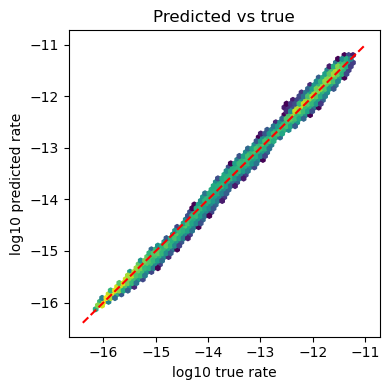

In [8]:
# plot training results

# Evaluate in physical units
model.eval()
with torch.no_grad():
    pred_norm = model(test_X).cpu().numpy()
pred = np.exp(pred_norm * y_std + y_mean) - EPS
r2 = 1 - np.sum((y_test - pred) ** 2) / np.sum((y_test - y_test.mean()) ** 2)
print(f"\nTest R^2 (physical units): {r2:.4f}")

# Quick diagnostic plot
try:
    fig, ax = plt.subplots(1, 1, figsize=(4, 4))
    ax.hexbin(np.log10(y_test + EPS), np.log10(pred + EPS), gridsize=60, bins="log")
    lims = ax.get_xlim()
    ax.plot(lims, lims, "r--")
    ax.set(xlabel="log10 true rate", ylabel="log10 predicted rate", title="Predicted vs true")
  
    plt.tight_layout()
    #plt.savefig(PATH + "diagnostics.png", dpi=150)
except ImportError:
    pass

## Export model to TorchScript, export weights and text vector¶

In [ ]:


# Save everything needed to reuse the model later (weights + scaling)
model_name = 'long_series'

torch.save({
    "state_dict": model.state_dict(),
    "x_mean": x_mean, "x_std": x_std, "y_mean": y_mean, "y_std": y_std,
    "log_cols": log_cols, "eps": eps,
}, path_data+f"{model_name}.pt")

x_mean, x_std = np.asarray(x_mean, float), np.asarray(x_std, float)
n_in = len(NAMES)
assert len(x_mean) == n_in == len(x_std), f"{n_in} FEATURES but x_mean has {len(x_mean)} entries"
assert np.asarray(X_test).shape[-1] == n_in, "X_test has a different number of columns than FEATURES"


# 2. TorchScript model with the transforms inside (raw float64 in, rate in mol/kg/s out)
class Emulator(nn.Module):
    def __init__(self, net, x_mean, x_std, y_mean, y_std, log_cols, eps):
        super().__init__()
        self.net = net.double()
        self.register_buffer("x_mean", torch.tensor(x_mean, dtype=torch.float64))
        self.register_buffer("x_std", torch.tensor(x_std, dtype=torch.float64))
        mask = torch.zeros(len(x_mean), dtype=torch.bool)
        mask[list(log_cols)] = True
        self.register_buffer("log_mask", mask)
        self.eps, self.y_mean, self.y_std = float(eps), float(y_mean), float(y_std)
 
    def forward(self, x):
        xl = torch.log(x.clamp(min=0.0) + self.eps)
        x = torch.where(self.log_mask, xl, x)          # log only the chosen columns
        x = (x - self.x_mean) / self.x_std
        out = self.net(x).squeeze(-1)
        return (torch.exp(out * self.y_std + self.y_mean) - self.eps).clamp(min=0.0)
 
 
emu = Emulator(copy.deepcopy(model.net).cpu(), x_mean, x_std, y_mean, y_std, log_cols, eps).eval()
example = torch.ones(2, n_in, dtype=torch.float64)      # shape/dtype only; values do not matter
torch.jit.trace(emu, example).save(path_data + f'{model_name}'+'-ts.pt')


# 3. check against the trained model on REAL rows (independent of the checkpoint contents)
rng = np.random.default_rng(0)
rows = np.asarray(X_test, float).reshape(-1, n_in)
rows = rows[np.isfinite(rows).all(axis=1)]
rows = rows[rng.choice(len(rows), 20, replace=False)]
ref = np.asarray(predict_rate(rows), float)
 
loaded = torch.jit.load(path_data + f'{model_name}'+'-ts.pt').eval()
with torch.no_grad():
    got = loaded(torch.as_tensor(rows)).numpy()
rel = np.abs(got - ref) / np.maximum(np.abs(ref), 1e-30)
print(f"max relative difference, TorchScript vs trained model: {rel.max():.2e}  (expect < 1e-4)")
if rel.max() > 1e-4:
    print("reference:", ref[:5])
    print("torchscript:", got[:5])
 
np.savetxt(path_data + f"remin_{model_name}_vectors.txt", np.column_stack([rows, ref]), fmt="%.9e")
written = [f'{model_name}-ts.pt', f"remin_{model_name}_vectors.txt"]
print("Wrote:", *written, sep="\n  ")


bad = ~np.isfinite(ref) | ~np.isfinite(got)
print("not finite:", bad.sum(), "of", len(ref), " | ref NaN:", np.isnan(ref).sum(), " torchscript NaN:", np.isnan(got).sum())
print("rows with a non-positive log column:", (rows[:, list(log_cols)] <= 0).any(axis=1).sum())
print("weights finite:", all(torch.isfinite(p).all().item() for p in model.parameters()))
print("scaling finite:", np.isfinite(x_mean).all(), np.isfinite(x_std).all(), np.isfinite(y_mean), np.isfinite(y_std))
print(np.column_stack([rows[bad], ref[bad], got[bad]])[:5])

print(type(model).__name__)

## Quick check on model predictors

Temperature 0.46241211891174316 8.806500911712646 13.577877044677734
Oxygen 0.00016729108756408095 0.0002469294558977708 0.00028320704586803913
Detritus 6.249356587773036e-10 1.9817028906743417e-08 7.121365683815384e-07
Zoo 1.9323267430593205e-09 1.9638043413650053e-09 3.3873238862724975e-06
target 3.18118741249644e-17 2.5761655822627554e-15 1.2474615090907193e-11


  0%|          | 0/500 [00:00<?, ?it/s]

/jobfs/182764681.gadi-pbs/ipykernel_1203356/2269104407.py:36: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_flat[ex_idx], feature_names=FEATURES, show=False)


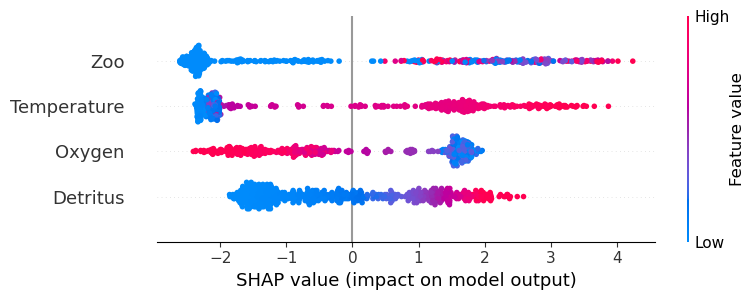

/jobfs/182764681.gadi-pbs/ipykernel_1203356/2269104407.py:41: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_flat[ex_idx], feature_names=FEATURES, plot_type="bar", show=False)


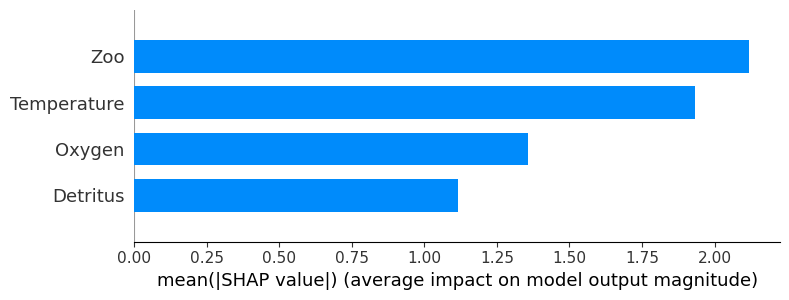

In [12]:
for i, n in enumerate(FEATURES):
    v = X[..., i]
    print(n, np.nanmin(v), np.nanmedian(v), np.nanmax(v))
print("target", np.nanmin(y), np.nanmedian(y), np.nanmax(y))

import logging, sys
logging.disable(sys.maxsize)
rng = np.random.default_rng(0)
 
# X_flat : RAW features (before any log transform or scaling), shape (n_samples, n_features).
#          Used only to colour the plots, so the colours show real units.
#X_flat = np.asarray(X_test, float).reshape(-1, len(NAMES))
#X_flat = X_flat[np.isfinite(X_flat).all(axis=1)]
X_flat = X_test

# Xn_all : the same samples as the network sees them: log transform (the log columns),
#          then (x - x_mean) / x_std. This is what SHAP perturbs.
Xn_all = Xte
 
 
def predict_norm(Xn):
    """Network output in normalised ln(rate) space, for inputs in network space."""
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(Xn, dtype=torch.float32).to(device)).cpu().numpy()
 
 
n_bg, n_explain = 100, 500
bg = shap.kmeans(Xn_all[rng.choice(len(Xn_all), min(2000, len(Xn_all)), replace=False)], n_bg)
ex_idx = rng.choice(len(Xn_all), min(n_explain, len(Xn_all)), replace=False)
 
explainer = shap.KernelExplainer(predict_norm, bg)
sv = explainer.shap_values(Xn_all[ex_idx], nsamples=200) * y_std     # ln(rate) units
 
plt.figure()
shap.summary_plot(sv, X_flat[ex_idx], feature_names=FEATURES, show=False)
plt.tight_layout()
plt.show()
 
plt.figure()
shap.summary_plot(sv, X_flat[ex_idx], feature_names=FEATURES, plot_type="bar", show=False)
plt.tight_layout()
plt.show()
 

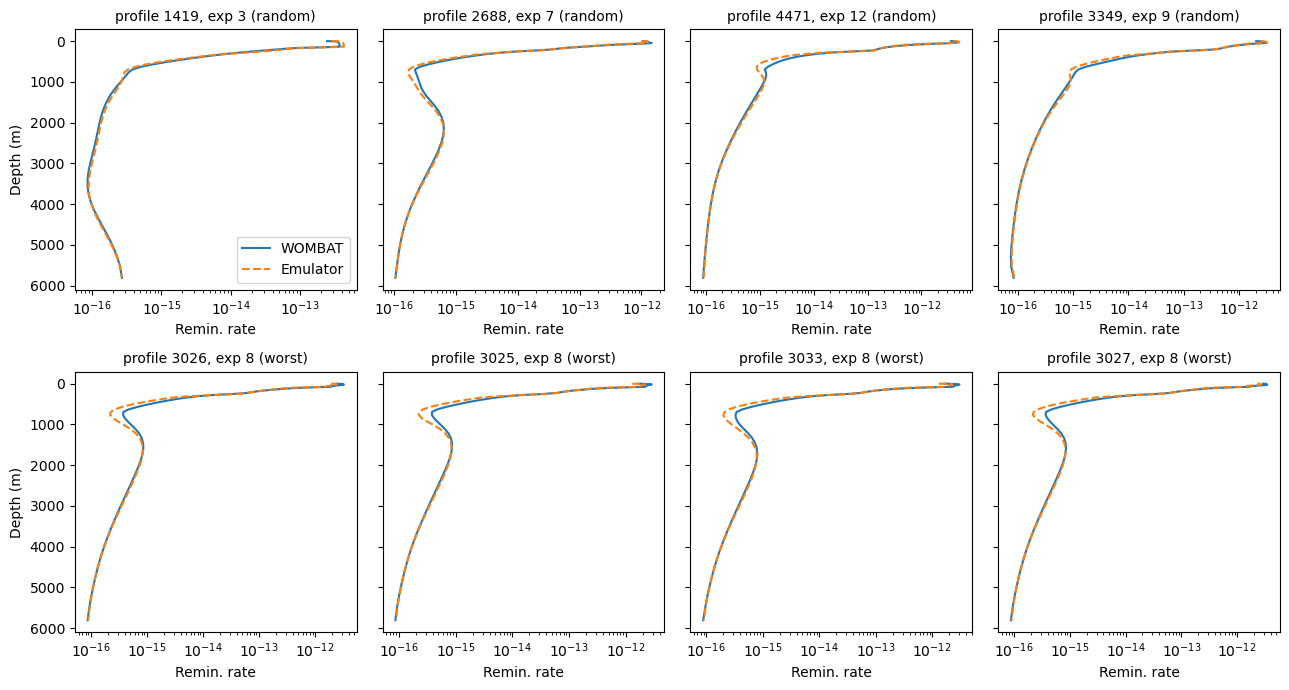

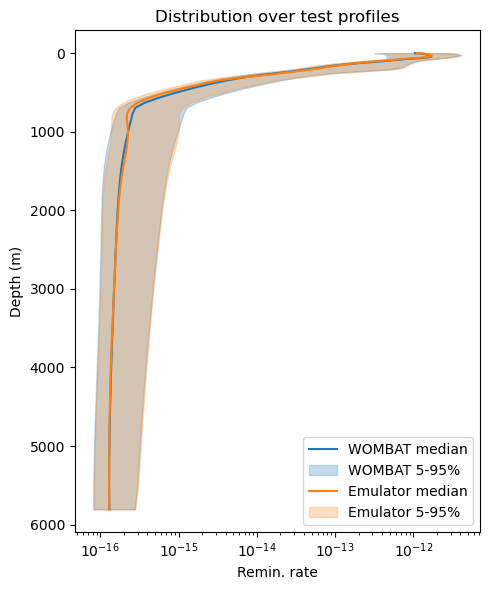

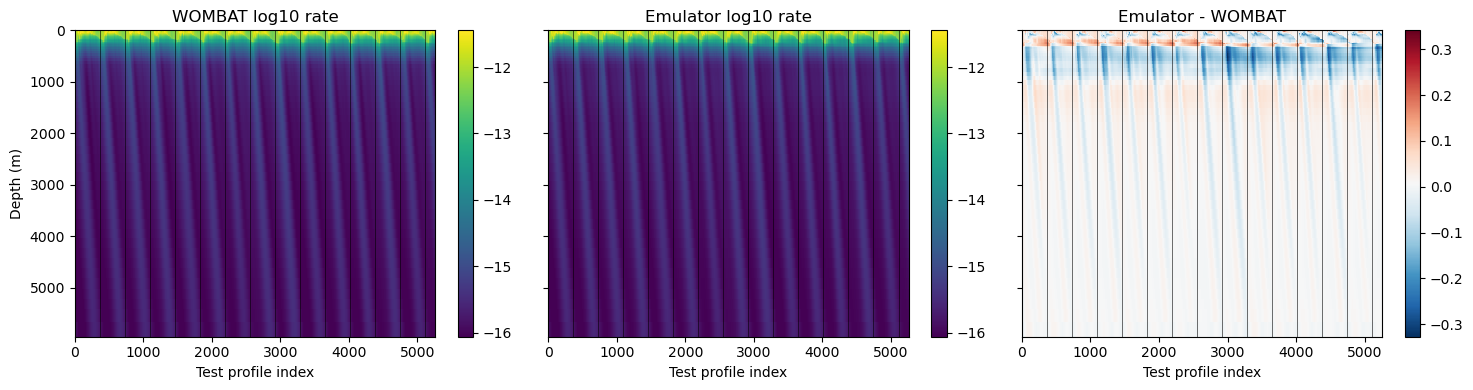

In [18]:

N_PER_EXP = 365      # profiles per experiment, if the test set holds several (else None)
rng = np.random.default_rng(0)
eps=EPS

# ---- shapes: predictions must have the same (n_profiles, n_depth) shape as the truth ----
n_z = len(depth)
obs = np.asarray(y_test, float).reshape(-1, n_z)            # (n_profiles, n_depth)
assert len(X_test) == obs.size, f"X_test has {len(X_test)} rows but y_test has {obs.size} values"
pred = predict_rate(X_test).reshape(obs.shape)              # <- the missing reshape
n_t = obs.shape[0]
 
# log10 without adding any offset: non-positive values simply become NaN (not plotted)
lo = np.log10(np.where(obs > 0, obs, np.nan))
lp = np.log10(np.where(pred > 0, pred, np.nan))
 
# ---- 1. example profiles: 4 random and the 4 worst (RMSE in log space per profile) ----
col_err = np.sqrt(np.nanmean((lp - lo) ** 2, axis=1))
worst = np.argsort(np.nan_to_num(col_err, nan=-1.0))[-4:][::-1]
rand = rng.choice(n_t, 4, replace=False)
picks = [(t, "random") for t in rand] + [(t, "worst") for t in worst]
 
fig, axes = plt.subplots(2, 4, figsize=(13, 7), sharey=True)
for ax, (t, kind) in zip(axes.flat, picks):
    ax.plot(obs[t], depth, label="WOMBAT")
    ax.plot(pred[t], depth, "--", label="Emulator")
    ax.set_xscale("log")
    exp_txt = f", exp {t // N_PER_EXP}" if N_PER_EXP else ""
    ax.set_title(f"profile {t}{exp_txt} ({kind})", fontsize=10)
    ax.set_xlabel("Remin. rate")
axes[0, 0].invert_yaxis()
axes[0, 0].set_ylabel("Depth (m)")
axes[1, 0].set_ylabel("Depth (m)")
axes[0, 0].legend()
plt.tight_layout()
plt.show()
 
# ---- 2. median and 5-95% range over the test profiles, at each depth ----
fig, ax = plt.subplots(figsize=(5, 6))
for arr, label, c in [(obs, "WOMBAT", "C0"), (pred, "Emulator", "C1")]:
    arr = np.where(arr > 0, arr, np.nan)
    p5, p50, p95 = np.nanpercentile(arr, [5, 50, 95], axis=0)
    ax.plot(p50, depth, color=c, label=f"{label} median")
    ax.fill_betweenx(depth, p5, p95, color=c, alpha=0.25, label=f"{label} 5-95%")
ax.set_xscale("log")
ax.invert_yaxis()
ax.set(xlabel="Remin. rate", ylabel="Depth (m)", title="Distribution over test profiles")
ax.legend()
plt.tight_layout()
plt.show()
 
# ---- 3. profile-depth sections: truth, emulator, difference ----
vmin, vmax = np.nanpercentile(lo, [1, 99])
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
t_axis = np.arange(n_t)
for ax, arr, title, kw in [
    (axes[0], lo, "WOMBAT log10 rate", dict(vmin=vmin, vmax=vmax, cmap="viridis")),
    (axes[1], lp, "Emulator log10 rate", dict(vmin=vmin, vmax=vmax, cmap="viridis")),
    (axes[2], (lp -lo), "Emulator - WOMBAT", dict( cmap="RdBu_r")),
]:
    m = ax.pcolormesh(t_axis, depth, arr.T, shading="auto", **kw)
    ax.set_title(title)
    ax.set_xlabel("Test profile index" if N_PER_EXP else "Test timestep")
    if N_PER_EXP:
        for b in range(N_PER_EXP, n_t, N_PER_EXP):
            ax.axvline(b, color="k", lw=0.4)            # experiment boundaries
    plt.colorbar(m, ax=ax)
axes[0].invert_yaxis()
axes[0].set_ylabel("Depth (m)")
plt.tight_layout()
plt.show()

## Compare multiple different MLP models on WOMBATmid data (same as training data)

In [16]:
# Compare several exported (TorchScript) emulator models on one test dataset.

# Needs in the session: ds_test, an xarray Dataset with dims (time, zl) that NONE of the models
# were trained or validated on, holding the input variables and the target (see Cell 1).
# Every model is called on its own input columns, but all models are scored on exactly the same
# samples. Errors are log10(prediction / truth) in "dex": +0.30 = twice too high, -0.30 = half.
# Log errors are used because the rates span about five decades with depth.
 
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
 
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="All-NaN slice encountered")

path_data =  '/../../../g/data/jk72/ao2582/PyTorch/training_data/'

 
# name: (exported TorchScript file, input features IN THE ORDER THE MODEL WAS TRAINED WITH)
MODELS = {
    "temp-oxy-det-fe":  (path_data + "temp_o2_det_fe-ts.pt", ["thetao", "o2", "det+bdet", "fe"]),
    "temp-oxy-det":     (path_data + "temp_o2_det-ts.pt", ["thetao","o2", "det+bdet"]),
    "temp-oxy-det-zoo": (path_data + "temp_o2_det_zoo-ts.pt", ["thetao","o2", "det+bdet", "zoo+mes"]),
    "temp-det-zoo": (path_data + "temp_det_zoo-ts.pt", ["thetao", "det+bdet", "zoo+mes"]),
     "temp-oxy-det-zoo-fe": (path_data + "temp_o2_det_zoo_fe-ts.pt", ["thetao","o2", "det+bdet", "zoo+mes", "fe"]),
}
 
# how to build each feature (training units: degC and mol/kg) from ds_test
FEATURE_RECIPES = {
    "thetao":   lambda ds: ds["thetao"],
    "o2":       lambda ds: ds["o2"],
    "det+bdet": lambda ds: ds["det"] + ds["bdet"],
    "fe":       lambda ds: ds["fe"],
    "zoo+mes":  lambda ds: ds["zoo"] + ds["mes"],
}
TARGET = "poc1remi"              # true rate in ds_test (mol/kg/s)
NONPOSITIVE_OK = {"thetao"}      # features allowed to be <= 0; rows with other non-positive inputs are dropped
TIME_SLICE = None                # e.g. slice(32 * 365, None) to use only the last years of ds_test
BANDS = [0, 100, 500, 1000, 2000, np.inf]     # depth bands (m) for the table
FACTOR = 1.5                     # "close enough" = within this factor
DEEP_FROM = 500                  # depth (m) for the "deep levels" panel of the error distribution
SECTION_RANGE = 0.5              # colour range (dex) of the time-depth sections
BATCH = 200_000                  # rows per call to the network
 
 

### load testing data

In [2]:
import xarray as xr
import pandas as pd
import glob
from dask import delayed, compute
import dask
import os
import matplotlib.pyplot as plt
import numpy as np


path_data =  '/../../../g/data/jk72/ao2582/PyTorch/shadow_data/run_shadow_iaf_1/output/'
#path_data =  '/../../../g/data/jk72/ao2582/PyTorch/shadow_data/run_shadow_iaf/output000/'
#path_data =  '/../../../g/data/jk72/ao2582/PyTorch/shadow_data/run_shadow_002/output/'
#path_data = '/scratch/zn44/ao2582/access-om3/archive/run_shadow_002/output003/'
files = glob.glob(path_data+ "*.nc")
#print(files)

params = ['thetao', 'mes', 'phy', 'zoo','det', 'dia', 'bdet', 'bac1','fe','o2', 'det_vmove', 'mlotst', 'detremi','bdetremi','poc1remi','poc1remi_nn']

# --- Optimized file loading function ---
def open_om3_variable(path_exp, varname):
    pattern = f"{path_exp}/access-om3.mom6.*d.{varname}.1day.mean.*.nc"
    files = sorted(glob.glob(pattern))
   # print(files)
    if not files:
        raise FileNotFoundError(f"No files found for variable {varname}")

    ds = xr.open_mfdataset(
        files,
        combine="nested",
        concat_dim="time",
        data_vars="minimal",
        coords="minimal",
        compat="override",
        decode_times=False,
        #chunks={"time": 365},  # Enable chunking per year
        #parallel=True  # Faster with many files
        )
    return ds

# Load all variables and merge
ds_list = []
for var in params:
    try:
        ds_var = open_om3_variable(path_data, var)
        ds_list.append(ds_var)
        ds_var.close()
    except FileNotFoundError:
        print(f" Missing variable {var}")


# Merge variables
ds = xr.merge(ds_list, compat="override", join="override")
# Fix time encoding
ds = ds.assign_coords(time=ds.time)  # Ensure time is coordinate
ds.time.attrs["units"] = "days since 0001-01-01 00:00:00"
ds.time.attrs["calendar"] = "julian"
ds_om3 = xr.decode_cf(ds, decode_timedelta=False).compute().mean(dim=['xh','yh'])


    
print('-- done')

ds_test = ds_om3.drop_vars('time_bnds')

-- done


### compare MLPs 

In [17]:
# %% CELL 2: build the common test samples, load the models, predict
def field(da):
    """Values as float64, dimensions ordered by name (time, zl)."""
    return da.squeeze().transpose("time", "zl").values.astype(float)
 
 
ds = ds_test if TIME_SLICE is None else ds_test.isel(time=TIME_SLICE)
zl = ds["zl"].values
needed = sorted({f for _, feats in MODELS.values() for f in feats})
unknown = [f for f in needed if f not in FEATURE_RECIPES]
if unknown:
    raise KeyError(f"no recipe in FEATURE_RECIPES for: {unknown}")
F = {n: field(FEATURE_RECIPES[n](ds)) for n in needed}
obs = field(ds[TARGET])
 
# one set of valid samples for ALL models (so no model is scored on easier points)
valid = np.isfinite(obs) & (obs > 0)
print(f"{obs.shape[0]} records x {obs.shape[1]} levels; usable target points: {int(valid.sum())}")
for n in needed:
    ok = np.isfinite(F[n]) & ((F[n] > 0) | (n in NONPOSITIVE_OK))
    print(f"  dropped because of {n}: {int((valid & ~ok).sum())} points")
    valid &= ok
print(f"samples used for every model: {int(valid.sum())}")
 
 
def predict(model, X):
    out = np.empty(len(X))
    with torch.no_grad():
        for i in range(0, len(X), BATCH):
            out[i:i + BATCH] = model(torch.as_tensor(X[i:i + BATCH], dtype=torch.float64)).numpy()
    return out
 
 
P, LR, zero_pct = {}, {}, {}
for name, (path, feats) in MODELS.items():
    model = torch.jit.load(path, map_location="cpu").eval()
    bufs = dict(model.named_buffers())
    if "x_mean" in bufs and len(bufs["x_mean"]) != len(feats):
        raise ValueError(f"{name}: the file expects {len(bufs['x_mean'])} inputs but {len(feats)} "
                         f"features are listed: {feats}")
    if "log_mask" in bufs:
        logged = [f for f, b in zip(feats, bufs["log_mask"].tolist()) if b]
        print(f"{name}: {len(feats)} inputs {feats}; log-transformed inside the model: {logged}")
    X = np.stack([F[n][valid] for n in feats], axis=-1)
    p = np.full(obs.shape, np.nan)
    p[valid] = predict(model, X)
    P[name] = p
    pos = valid & (p > 0)
    zero_pct[name] = 100 * float((valid & ~pos).sum()) / float(valid.sum())
    # log ratio; points where the prediction is not positive cannot be put on a log scale
    LR[name] = np.where(pos, np.log10(np.where(pos, p, 1.0) / np.where(pos, obs, 1.0)), np.nan)
colors = {name: f"C{i}" for i, name in enumerate(MODELS)}
 
 


12053 records x 75 levels; usable target points: 903975
  dropped because of det+bdet: 0 points
  dropped because of fe: 0 points
  dropped because of o2: 0 points
  dropped because of thetao: 0 points
  dropped because of zoo+mes: 0 points
samples used for every model: 903975
temp-oxy-det-fe: 4 inputs ['thetao', 'o2', 'det+bdet', 'fe']; log-transformed inside the model: ['det+bdet', 'fe']
temp-oxy-det: 3 inputs ['thetao', 'o2', 'det+bdet']; log-transformed inside the model: ['det+bdet']
temp-oxy-det-zoo: 4 inputs ['thetao', 'o2', 'det+bdet', 'zoo+mes']; log-transformed inside the model: ['det+bdet', 'zoo+mes']
temp-det-zoo: 3 inputs ['thetao', 'det+bdet', 'zoo+mes']; log-transformed inside the model: ['det+bdet', 'zoo+mes']
temp-oxy-det-zoo-fe: 5 inputs ['thetao', 'o2', 'det+bdet', 'zoo+mes', 'fe']; log-transformed inside the model: ['det+bdet', 'zoo+mes', 'fe']


In [18]:
# %% CELL 3: summary tables
rows = {}
for name, (path, feats) in MODELS.items():
    m = np.isfinite(LR[name])
    e = LR[name][m]
    lo = np.log10(obs[m])
    lp = lo + e
    rows[name] = {
        "inputs": len(feats),
        "bias (dex)": e.mean(),
        "RMSE (dex)": np.sqrt((e ** 2).mean()),
        f"within x{FACTOR:g} (%)": 100 * np.mean(np.abs(e) < np.log10(FACTOR)),
        "within x2 (%)": 100 * np.mean(np.abs(e) < np.log10(2)),
        "R2 log": 1 - ((lp - lo) ** 2).sum() / ((lo - lo.mean()) ** 2).sum(),
        "R2 physical": 1 - ((P[name][m] - obs[m]) ** 2).sum() / ((obs[m] - obs[m].mean()) ** 2).sum(),
        "% predictions <= 0": zero_pct[name],
    }
summary = pd.DataFrame(rows).T.sort_values("RMSE (dex)")
display(summary.round(3))
print("RMSE and bias are over points where the prediction is positive; '% predictions <= 0' "
      "shows how many points that excludes, so read the two together.")
 
band_labels = [f"{lo:g}-{hi:g} m" for lo, hi in zip(BANDS[:-1], BANDS[1:])]
band_rmse = {}
for name in MODELS:
    r = []
    for lo, hi in zip(BANDS[:-1], BANDS[1:]):
        x = LR[name][:, (zl >= lo) & (zl < hi)]
        x = x[np.isfinite(x)]
        r.append(np.sqrt((x ** 2).mean()) if x.size else np.nan)
    band_rmse[name] = r
display(pd.DataFrame(band_rmse, index=band_labels).T.loc[summary.index].round(3)
        .rename_axis("RMSE (dex) by depth band"))
 

,inputs,bias (dex),RMSE (dex),within x1.5 (%),within x2 (%),R2 log,R2 physical,% predictions <= 0
temp-det-zoo,3.0,0.001,0.079,95.783,99.525,0.998,0.960,0.0
temp-oxy-det-zoo-fe,5.0,0.005,0.080,95.560,99.281,0.998,0.982,0.0
temp-oxy-det-zoo,4.0,0.001,0.090,94.061,98.781,0.997,0.971,0.0
temp-oxy-det-fe,4.0,-0.014,0.223,80.164,92.773,0.984,0.940,0.0
temp-oxy-det,3.0,-0.015,0.231,83.147,93.190,0.983,0.966,0.0


RMSE and bias are over points where the prediction is positive; '% predictions <= 0' shows how many points that excludes, so read the two together.


,0-100 m,100-500 m,500-1000 m,1000-2000 m,2000-inf m
RMSE (dex) by depth band,,,,,
temp-det-zoo,0.081,0.092,0.102,0.085,0.053
temp-oxy-det-zoo-fe,0.063,0.085,0.132,0.102,0.057
temp-oxy-det-zoo,0.075,0.128,0.112,0.093,0.057
temp-oxy-det-fe,0.138,0.168,0.253,0.285,0.287
temp-oxy-det,0.109,0.178,0.277,0.286,0.312


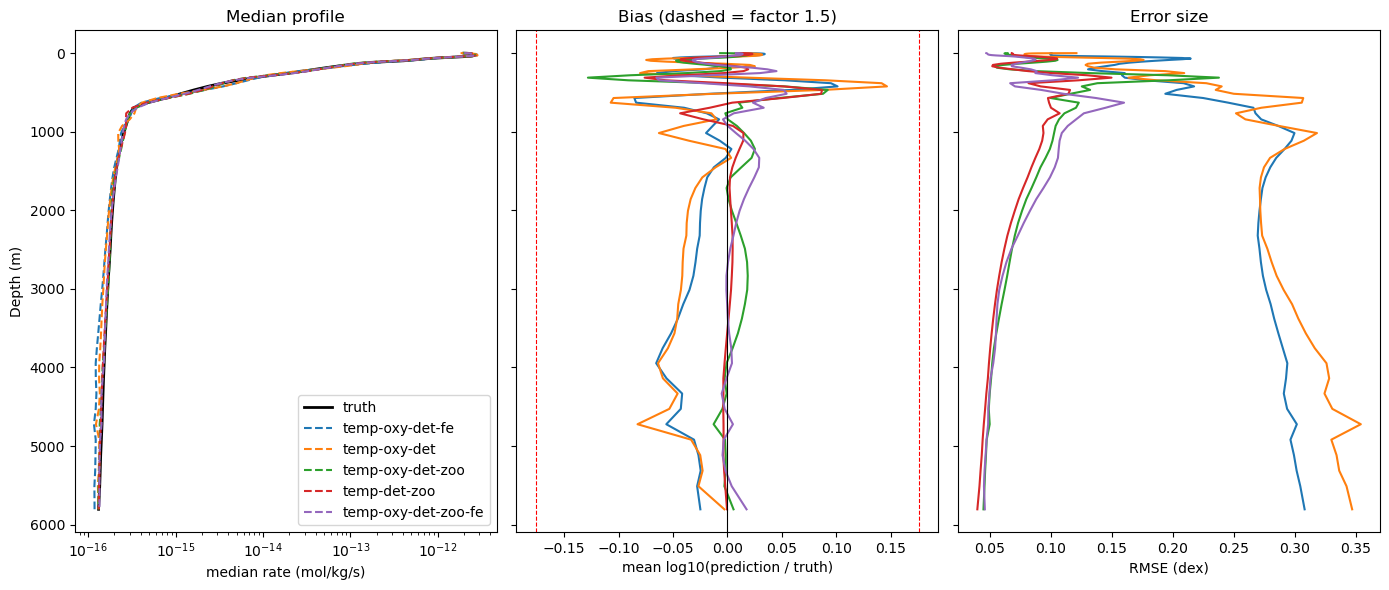

In [19]:
# %% CELL 4: figure 1 - profiles
fig, ax = plt.subplots(1, 3, figsize=(14, 6), sharey=True)
ax[0].plot(np.nanmedian(np.where(valid, obs, np.nan), axis=0), zl, color="k", lw=2, label="truth")
for name in MODELS:
    ax[0].plot(np.nanmedian(np.where(valid, P[name], np.nan), axis=0), zl,
               color=colors[name], ls="--", label=name)
    ax[1].plot(np.nanmean(LR[name], axis=0), zl, color=colors[name], label=name)
    ax[2].plot(np.sqrt(np.nanmean(LR[name] ** 2, axis=0)), zl, color=colors[name], label=name)
ax[0].set_xscale("log")
ax[0].set(xlabel="median rate (mol/kg/s)", ylabel="Depth (m)", title="Median profile")
ax[0].legend()
ax[1].axvline(0, color="k", lw=0.8)
for s in (-np.log10(FACTOR), np.log10(FACTOR)):
    ax[1].axvline(s, color="r", ls="--", lw=0.8)
ax[1].set(xlabel="mean log10(prediction / truth)", title=f"Bias (dashed = factor {FACTOR:g})")
ax[2].set(xlabel="RMSE (dex)", title="Error size")
ax[0].invert_yaxis()
plt.tight_layout()
plt.show()


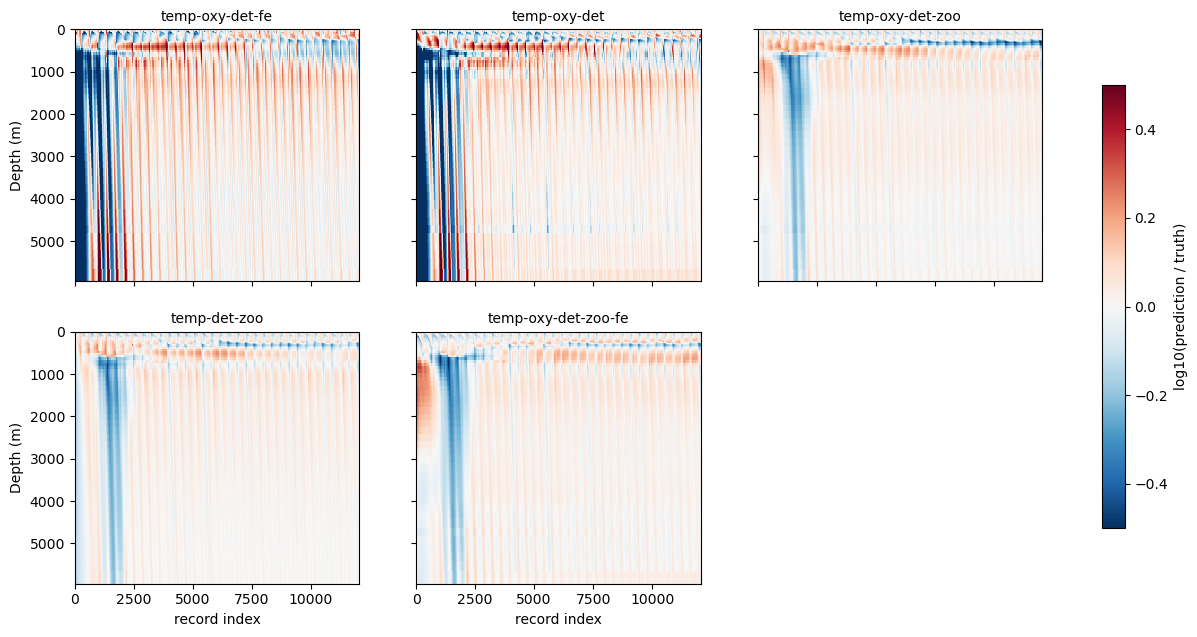

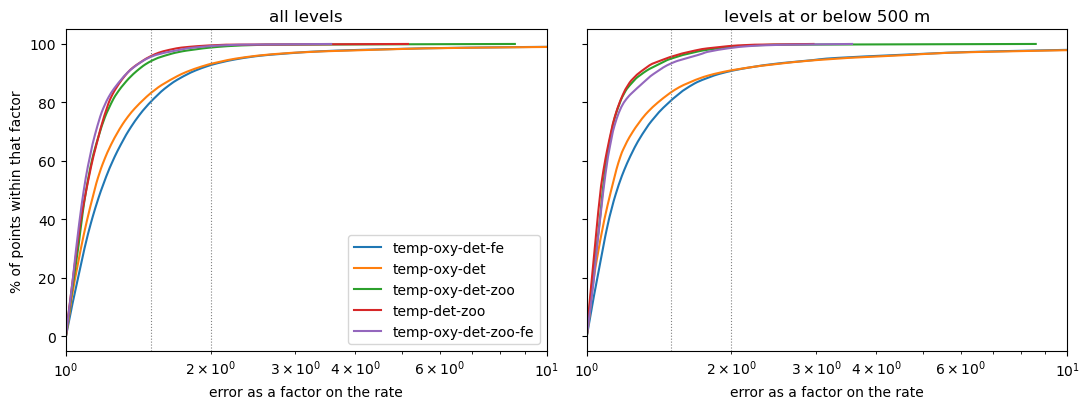

In [21]:
# %% CELL 5: figure 2 - time-depth sections of the error, one panel per model
n = len(MODELS)
ncols = min(n, 3)
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.6 * nrows), sharex=True, sharey=True,
                         squeeze=False)
t_axis = np.arange(obs.shape[0])
for a, name in zip(axes.ravel(), MODELS):
    mesh = a.pcolormesh(t_axis, zl, LR[name].T, cmap="RdBu_r", vmin=-SECTION_RANGE,
                        vmax=SECTION_RANGE, shading="auto")
    a.set_title(name, fontsize=10)
for a in axes.ravel()[n:]:
    a.set_visible(False)
axes[0, 0].invert_yaxis()
for a in axes[-1]:
    a.set_xlabel("record index")
for a in axes[:, 0]:
    a.set_ylabel("Depth (m)")
fig.colorbar(mesh, ax=axes.ravel().tolist(), label="log10(prediction / truth)", shrink=0.8)
plt.show()
 
 
# %% CELL 6: figure 3 - how many points are within a given factor?
qs = np.linspace(0, 1, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for k, (title, sel) in enumerate([("all levels", np.ones(len(zl), bool)),
                                  (f"levels at or below {DEEP_FROM} m", zl >= DEEP_FROM)]):
    for name in MODELS:
        e = np.abs(LR[name][:, sel])
        e = e[np.isfinite(e)]
        if e.size:
            ax[k].plot(10 ** np.quantile(e, qs), 100 * qs, color=colors[name], label=name)
    for f in (FACTOR, 2):
        ax[k].axvline(f, color="gray", ls=":", lw=0.8)
    ax[k].set_xscale("log")
    ax[k].set_xlim(1, 10)
    ax[k].set(xlabel="error as a factor on the rate", title=title)
ax[0].set_ylabel("% of points within that factor")
ax[0].legend(loc="lower right")
plt.tight_layout()
plt.show()